# Reproducing: *Hidden Color Contrast Violations in Mobile User Interfaces Under Color Vision Deficiency*

This notebook regenerates **every table, figure, and statistic** in the paper, directly from the result files.

- **Extraction stage** (raw RICO screenshots + view-hierarchy JSON, to per-element foreground/background colors and contrast) lives in **`cvd_pipeline.py`**. It produced `results/cvd_results_random.csv` (RICO) and `results/clay_results.csv` (CLAY).
- **This notebook** reproduces everything downstream of extraction, from those CSVs, plus the manual-label files for extraction accuracy.
- In every cell, bracketed values `[...]` are the numbers exactly as they appear in the paper, for side-by-side checking.

**Requirements:** `numpy`, `matplotlib`, and (for Sec. IV-F and Sec. IV-G) `daltonlens`.

In [1]:
import csv, math, numpy as np, matplotlib
import matplotlib.pyplot as plt

# readable figure fonts
matplotlib.rcParams.update({
    "font.size": 13, "axes.labelsize": 14, "axes.titlesize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12, "figure.dpi": 120,
})
from collections import defaultdict, Counter

T = lambda s: str(s).strip().lower() == "true"
def wilson(k, n, z=1.96):
    p=k/n; d=1+z*z/n; c=(p+z*z/(2*n))/d
    h=z*math.sqrt(p*(1-p)/n + z*z/(4*n*n))/d
    return round(100*(c-h),2), round(100*(c+h),2)
def component(c):                        # mutually-exclusive class (Button > EditText > TextView)
    if "Button" in c and "ImageButton" not in c: return "Button"
    if "EditText" in c: return "EditText"
    if "TextView" in c: return "TextView"
    return "Other"

R  = list(csv.DictReader(open("results/cvd_results_random.csv", encoding="utf-8")))
P  = [r for r in R if T(r["normal_pass"])]           # WCAG-passing = population at risk
H  = [r for r in P if T(r["any_hidden"])]            # hidden violations
CL = [r for r in csv.DictReader(open("results/clay_results.csv", encoding="utf-8")) if T(r["normal_pass"])]
CH = [r for r in CL if T(r["any_hidden"])]
print(f"RICO loaded: {len(R):,} elements | {len(P):,} passing | {len(H)} hidden")
print(f"CLAY loaded: {len(CL):,} passing | {len(CH)} hidden")

RICO loaded: 42,285 elements | 21,915 passing | 601 hidden
CLAY loaded: 22,252 passing | 517 hidden


## Sec. IV-A and Abstract: Overall Prevalence

In [2]:
print(f"Total elements     : {len(R):,}              [42,285]")
print(f"Pass normal WCAG   : {len(P):,} ({100*len(P)/len(R):.1f}%)   [21,915 / 51.8%]")
print(f"Hidden violations  : {len(H)} ({100*len(H)/len(P):.2f}%)        [601 / 2.74%]")
print(f"95% Wilson CI      : {wilson(len(H),len(P))}         [2.53, 2.97]")
print(f"About one in {round(len(P)/len(H))} passing elements        [one in 36]")

Total elements     : 42,285              [42,285]
Pass normal WCAG   : 21,915 (51.8%)   [21,915 / 51.8%]
Hidden violations  : 601 (2.74%)        [601 / 2.74%]
95% Wilson CI      : (2.53, 2.97)         [2.53, 2.97]
About one in 36 passing elements        [one in 36]


## Sec. IV-B: Extraction Accuracy (from manual labels)

In [3]:
def accuracy(files):
    m=n=0
    for f in files:
        c=Counter(x["label"].strip().lower() for x in csv.DictReader(open(f)))
        m+=c["match"]; n+=c["match"]+c["no"]          # 'skip' = not judgeable, excluded
    return m,n
m,n=accuracy(["extraction_labels.csv","extraction_labels_2.csv"])
print(f"General accuracy  : {m}/{n} = {100*m/n:.0f}%  CI {wilson(m,n)}   [81% / 74-87]")
m,n=accuracy(["extraction_labels_flagged.csv"])
print(f"Flagged precision : {m}/{n} = {100*m/n:.0f}%  CI {wilson(m,n)}   [78% / 64-87]")
m,n=accuracy(["clay_extraction_labels_flagged.csv"])
print(f"CLAY precision    : {m}/{n} = {100*m/n:.0f}%   [91%]")
print("Mismatch reasons  :", dict(Counter(x["reason"] for x in csv.DictReader(open("extraction_reasons.csv")))), " [bad_box dominant]")

General accuracy  : 108/133 = 81%  CI (73.72, 86.93)   [81% / 74-87]
Flagged precision : 38/49 = 78%  CI (64.12, 86.98)   [78% / 64-87]
CLAY precision    : 61/67 = 91%   [91%]
Mismatch reasons  : {'no_text': 1, 'wrong_color': 8, 'bad_box': 25, 'actually_fine': 2}  [bad_box dominant]


## Sec. IV-C and Table I: Distribution Across CVD Types, and Cochran's Q

In [4]:
types=["protan","deutan","tritan"]; Hd=lambda r,t: T(r[f"{t}_hidden"])
counts={t:sum(1 for r in P if Hd(r,t)) for t in types}
print("Table I  (count / rate-of-passing):")
for t,name in zip(types,["Protanopia","Deuteranopia","Tritanopia"]):
    print(f"  {name:13s} {counts[t]:4d}   {100*counts[t]/len(P):.2f}%")
print("  [362/1.65, 231/1.05, 305/1.39]")
only={t:sum(1 for r in P if Hd(r,t) and all(not Hd(r,u) for u in types if u!=t)) for t in types}
allthree=sum(1 for r in P if all(Hd(r,t) for t in types))
print(f"Only-one {only} | all-three {allthree} | type-specific {sum(only.values())}   [145/150/20, 11, 315]")
k=3; C=list(counts.values()); ts=sum(only.values()); two=len(H)-ts-allthree
sR=ts+2*two+3*allthree; sR2=ts+4*two+9*allthree
Q=(k-1)*(k*sum(c*c for c in C)-sum(C)**2)/(k*sR-sR2)
print(f"Cochran's Q = {Q:.1f}, df=2, p<0.001   [Q=43.9]")

Table I  (count / rate-of-passing):
  Protanopia     362   1.65%
  Deuteranopia   231   1.05%
  Tritanopia     305   1.39%
  [362/1.65, 231/1.05, 305/1.39]
Only-one {'protan': 145, 'deutan': 150, 'tritan': 20} | all-three 11 | type-specific 315   [145/150/20, 11, 315]
Cochran's Q = 43.9, df=2, p<0.001   [Q=43.9]


## Sec. IV-D and Table II: Component-Level Analysis, and two-proportion z-test

In [5]:
g=defaultdict(lambda:[0,0])
for r in P:
    c=component(r["element_class"]); g[c][0]+=1; g[c][1]+=T(r["any_hidden"])
print("Table II:")
for c in ["Button","TextView","EditText"]:
    print(f"  {c:9s} pass={g[c][0]:5d} hidden={g[c][1]:3d}  rate={100*g[c][1]/g[c][0]:.2f}%")
print("  [2019/108/5.35, 19553/482/2.47, 343/11/3.21]")
b=g["Button"]; nb=[len(P)-b[0], len(H)-b[1]]
p1=b[1]/b[0]; p2=nb[1]/nb[0]; pp=len(H)/len(P)
z=(p1-p2)/math.sqrt(pp*(1-pp)*(1/b[0]+1/nb[0]))
print(f"Non-button {nb[1]}/{nb[0]} = {100*p2:.2f}% ; two-proportion z = {z:.1f}, p<0.001   [2.48% / z=7.5]")

Table II:
  Button    pass= 2019 hidden=108  rate=5.35%
  TextView  pass=19553 hidden=482  rate=2.47%
  EditText  pass=  343 hidden= 11  rate=3.21%
  [2019/108/5.35, 19553/482/2.47, 343/11/3.21]
Non-button 493/19896 = 2.48% ; two-proportion z = 7.5, p<0.001   [2.48% / z=7.5]


## Sec. IV-E: Threshold-Proximity Effect

In [6]:
band=sum(1 for r in H if 4.5<=float(r["normal_ratio"])<5.5)
mn=np.mean([float(r["normal_ratio"]) for r in P]); md_=np.mean([float(r["deutan_ratio"]) for r in P])
print(f"Hidden violations in [4.5,5.5): {band}/{len(H)} = {100*band/len(H):.1f}%   [595 / 99.0%]")
print(f"Mean passing contrast normal vs deuteranopia: {mn:.2f} vs {md_:.2f}   [10.22 / 10.21]")

Hidden violations in [4.5,5.5): 595/601 = 99.0%   [595 / 99.0%]
Mean passing contrast normal vs deuteranopia: 10.22 vs 10.21   [10.22 / 10.21]


## Sec. IV-F and Fig. 4: Severity Gradient (requires `daltonlens`)

Severity 0.1 -> 0.35%    ...    1.0 -> 2.72%   [0.35% -> 2.74%]


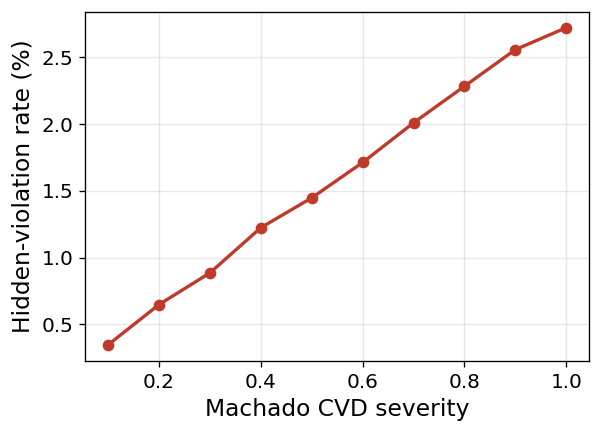

In [7]:
from daltonlens import simulate
W=np.array([0.2126,0.7152,0.0722])
def _lin(a): a=a/255.0; return np.where(a<=0.04045,a/12.92,((a+0.055)/1.055)**2.4)
def _cr(c1,c2):
    L1=_lin(c1.astype(float))@W; L2=_lin(c2.astype(float))@W
    return (np.maximum(L1,L2)+0.05)/(np.minimum(L1,L2)+0.05)
fg=np.array([[int(r["fg_r"]),int(r["fg_g"]),int(r["fg_b"])] for r in R],np.uint8)
bg=np.array([[int(r["bg_r"]),int(r["bg_g"]),int(r["bg_b"])] for r in R],np.uint8)
npass=np.array([T(r["normal_pass"]) for r in R])
defs=[simulate.Deficiency.PROTAN,simulate.Deficiency.DEUTAN,simulate.Deficiency.TRITAN]
def rate_at(sim,sev):
    anyh=np.zeros(len(R),bool)
    for d in defs:
        sf=sim.simulate_cvd(fg.reshape(-1,1,3),d,severity=sev).reshape(-1,3)
        sb=sim.simulate_cvd(bg.reshape(-1,1,3),d,severity=sev).reshape(-1,3)
        anyh|=(npass & (_cr(sf,sb)<4.5))
    return anyh.sum()/npass.sum()
sevs=np.arange(0.1,1.001,0.1); mac=simulate.Simulator_Machado2009()
rates=[rate_at(mac,s) for s in sevs]
print(f"Severity 0.1 -> {100*rates[0]:.2f}%    ...    1.0 -> {100*rates[-1]:.2f}%   [0.35% -> 2.74%]")
plt.figure(figsize=(5.2,3.8))
plt.plot(sevs,[100*x for x in rates],"o-",color="#c0392b",linewidth=2,markersize=6)
plt.xlabel("Machado CVD severity"); plt.ylabel("Hidden-violation rate (%)")
plt.grid(alpha=.3); plt.tight_layout(); plt.savefig("severity_reproduced.png",bbox_inches="tight"); plt.show()

## Sec. IV-G: Model Robustness (Vienot and Brettel; requires `daltonlens`)

In [8]:
mach=np.array([T(r["any_hidden"]) for r in R])          # Machado, from CSV
def model_hidden(sim):
    anyh=np.zeros(len(R),bool)
    for d in defs:
        sf=sim.simulate_cvd(fg.reshape(-1,1,3),d,severity=1.0).reshape(-1,3)
        sb=sim.simulate_cvd(bg.reshape(-1,1,3),d,severity=1.0).reshape(-1,3)
        anyh|=(npass & (_cr(sf,sb)<4.5))
    return anyh
vi=model_hidden(simulate.Simulator_Vienot1999()); br=model_hidden(simulate.Simulator_Brettel1997()); Pn=npass.sum()
print(f"Vienot {100*vi.sum()/Pn:.1f}%   Brettel {100*br.sum()/Pn:.1f}%   Machado 2.7%   [2.0 / 1.9 / 2.7]")
print(f"Flagged by all three models: {(mach&vi&br).sum()}   [~327; +-1% from daltonlens version]")
print(f"Vienot flags in Machado {100*(vi&mach).sum()/vi.sum():.0f}%  Brettel {100*(br&mach).sum()/br.sum():.0f}%   [96 / 91]")

Vienot 2.0%   Brettel 1.9%   Machado 2.7%   [2.0 / 1.9 / 2.7]
Flagged by all three models: 324   [~327; +-1% from daltonlens version]
Vienot flags in Machado 95%  Brettel 91%   [96 / 91]


## Sec. IV-H: Cross-Dataset Replication (CLAY)

In [9]:
print(f"CLAY passing {len(CL):,} ; hidden {len(CH)} = {100*len(CH)/len(CL):.2f}%  CI {wilson(len(CH),len(CL))}   [2.32 / 2.13-2.53]")
band=sum(1 for r in CH if 4.5<=float(r["normal_ratio"])<5.5)
cb=[r for r in CL if "BUTTON" in r.get("clay_type","").upper()]; cbh=sum(1 for r in cb if T(r["any_hidden"]))
cn=[r for r in CL if r not in cb]; cnh=sum(1 for r in cn if T(r["any_hidden"]))
pp=len(CH)/len(CL); zc=(cbh/len(cb)-cnh/len(cn))/math.sqrt(pp*(1-pp)*(1/len(cb)+1/len(cn)))
print(f"In-band {100*band/len(CH):.1f}%   Button {100*cbh/len(cb):.2f}% (z={zc:.1f} vs rest)   [99.2 / 2.96 / 3.0]")

CLAY passing 22,252 ; hidden 517 = 2.32%  CI (2.13, 2.53)   [2.32 / 2.13-2.53]


In-band 99.2%   Button 2.96% (z=3.0 vs rest)   [99.2 / 2.96 / 3.0]


## Fig. 3: Normal vs. Minimum-CVD Contrast Scatter

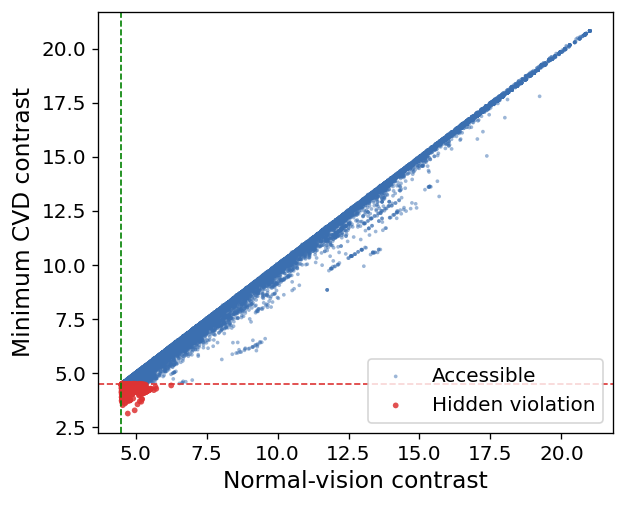

In [10]:
x=[float(r["normal_ratio"]) for r in P]
y=[min(float(r["protan_ratio"]),float(r["deutan_ratio"]),float(r["tritan_ratio"])) for r in P]
hid=[T(r["any_hidden"]) for r in P]
plt.figure(figsize=(5.4,4.4))
plt.scatter([x[i] for i in range(len(x)) if not hid[i]],[y[i] for i in range(len(x)) if not hid[i]],s=5,c="#3b6fb0",alpha=.5,label="Accessible",edgecolors="none")
plt.scatter([x[i] for i in range(len(x)) if hid[i]],[y[i] for i in range(len(x)) if hid[i]],s=12,c="#d33",alpha=.85,label="Hidden violation",edgecolors="none")
plt.axhline(4.5,ls="--",c="#d33",lw=1); plt.axvline(4.5,ls="--",c="green",lw=1)
plt.xlabel("Normal-vision contrast"); plt.ylabel("Minimum CVD contrast"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig("scatter_reproduced.png",bbox_inches="tight"); plt.show()

## Limitations: Screen-Clustered Bootstrap

In [11]:
scr=defaultdict(lambda:[0,0,0,0,0,0])
for r in P:
    s=scr[r["screenshot_id"]]; isb=component(r["element_class"])=="Button"; h=T(r["any_hidden"])
    s[0]+=1; s[1]+=h
    if isb: s[2]+=1; s[3]+=h
    else: s[4]+=1; s[5]+=h
a=np.array(list(scr.values()),float); rng=np.random.default_rng(0); B=3000
rates=np.empty(B); bsig=0
for i in range(B):
    ss=a[rng.integers(0,len(a),len(a))].sum(0); rates[i]=ss[1]/ss[0]
    if ss[3]/ss[2] > ss[5]/ss[4]: bsig+=1
print(f"Screen-clustered bootstrap 95% CI: [{100*np.percentile(rates,2.5):.2f}, {100*np.percentile(rates,97.5):.2f}]   [2.39, 3.11]")
print(f"Button rate > non-button in {100*bsig/B:.0f}% of resamples   [100%]")
print("All paper numbers reproduced.")

Screen-clustered bootstrap 95% CI: [2.39, 3.11]   [2.39, 3.11]
Button rate > non-button in 100% of resamples   [100%]
All paper numbers reproduced.
